In [19]:
import pandas as pd
import math
import pypsa



# Einlesen Wind, Solar, Demand_Paper

/var/folders/j_/qjf5tyz945q4jx1pg2sf76yc0000gn/T/ipykernel_13761/3357993483.py:6: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  ts_pv.rename(columns={"G(i)": "pv_profil"}, inplace=True)


<Axes: title={'center': 'PV-Leistungssignal'}, xlabel='Zeit', ylabel='[W/m^2]'>

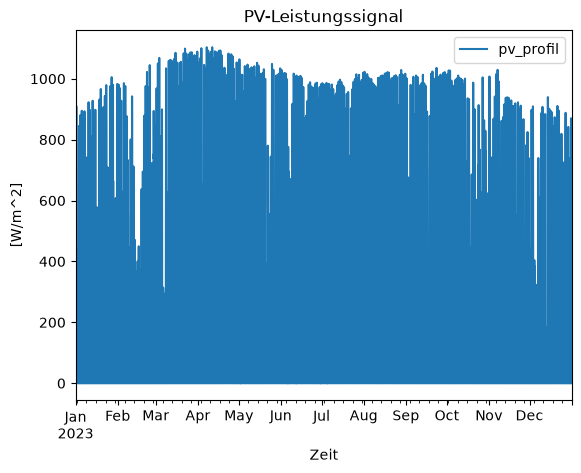

In [20]:
## Einlesen des PV-Leistungsprofils
ts_pv = pd.read_csv("data/raw/Timeseries_35.754_-5.689_SA3_1kWp_crystSi_14_32deg_8deg_2023_2023.csv", index_col="time", skiprows=10)
ts_pv.index = pd.to_datetime(ts_pv.index, format="%Y%m%d:%H%M", errors="coerce").floor("h")
ts_pv = ts_pv[ts_pv.index.notna()]  # Legenden-Zeilen am Dateiende entfernen
ts_pv = ts_pv[["G(i)"]].astype(float)
ts_pv.rename(columns={"G(i)": "pv_profil"}, inplace=True) 

ts_pv.head()
ts_pv.plot(title="PV-Leistungssignal", ylabel="[W/m^2]", xlabel="Zeit")

<Axes: title={'center': 'Wind-Leistungssignal'}, xlabel='Zeit', ylabel='Leistung [W]'>

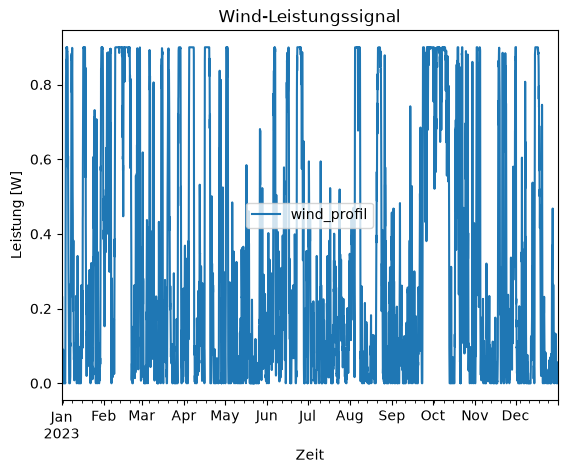

In [21]:
ts_wind = pd.read_csv("data/processed/wind_lastprofil_2023.csv", parse_dates=["time"], index_col="time") # normalisiert
ts_wind.head(-1)
ts_wind.plot(title="Wind-Leistungssignal", ylabel="Leistung [W]", xlabel="Zeit")

In [22]:
df_load = pd.read_csv("data/hotmaps_task_2.7_load_profile_industry_paper_yearlong_2018.csv") # normalisiert
ts_load = df_load[df_load["NUTS0_code"] == "DE"]
ts_load = ts_load["load"]
ts_load.index = ts_wind.index
#ts_load.index = ts_wind.index
ts_load.head(-1)

time
2023-01-01 00:00:00    110.104142
2023-01-01 01:00:00    110.123274
2023-01-01 02:00:00    110.188837
2023-01-01 03:00:00    110.359945
2023-01-01 04:00:00    110.716087
                          ...    
2023-12-31 18:00:00    114.393471
2023-12-31 19:00:00    114.217197
2023-12-31 20:00:00    114.092858
2023-12-31 21:00:00    113.974490
2023-12-31 22:00:00    113.864562
Name: load, Length: 8759, dtype: float64

# Einladen der notwendigen Profile für den Schiffstransport

In [ ]:
ship_profiles = pd.read_csv("Data/ship_profiles/ship_sea.csv")

dme_load_profile = ship_profiles["dme_load_morocco"]
dme_deload_profile = ship_profiles["dme_deload_rotterdam"]

co2_load_profile = ship_profiles["co2_load_rotterdam"]
co2_deload_profile = ship_profiles["co2_deload_morocco"]

ship_profile = ship_profiles["at_sea"]

dme_source = ship_profiles["import_dme"]
co2_source = ship_profiles["import_co2"]


,beladung,entladung
time,,
2023-01-01 00:00:00,1,0
2023-01-01 01:00:00,1,0
2023-01-01 02:00:00,1,0
2023-01-01 03:00:00,1,0
2023-01-01 04:00:00,1,0
...,...,...
2023-12-31 18:00:00,0,0
2023-12-31 19:00:00,0,0
2023-12-31 20:00:00,0,0


## Parameter

In [ ]:
# PV
pv_opex = 0.05 # €/kWh
# Wind
wind_opex = 0.05 # €/kWh

# electrolyzer
electrolyzer_efficiency = 0.7 

# battery
battery_efficiency_total = 0.9
battery_efficiency_one_way = math.sqrt(battery_efficiency_total)
battery_capex = 100 # €/kWh
battery_lifetime = 10 # years
battery_standby_loss = 0.001 # %/h

# hydrogen storage
hydrogen_storage_standby_loss = 0.0001 # %/h

# water 
saltwater_cost = 0.001 # €/m^3
desalination_opex = 0.05 # €/m^3
desalination_capex = 1000 # €/m^3
desalination_efficiency = 0.5 # muss recherchiert werden

# DME synthesis
dme_synthese_efficiency_co2 = -1 # muss recherchiert werden
dme_synthese_efficiency_h20 = 0.5 # muss recherchiert werden
dme_synthese_efficiency_dme = 0.5 # muss recherchiert werden
dme_standing_loss = 0.0001 # %/h
dme_store_capex=80 # in €/MWh

# DAC
dac_opex = 0.05 # €/kg
dac_capex = 100 # €/kg

# CO2 Storage
co2_standing_loss = 0.0001 # %/h
co2_capex = 80 # €/kg

# Schiffstransport
ship_dme_enom = 15100 # in MWh
ship_co2_enom = ship_dme_enom * 0.215 # in t
ship_fuel_enom = 10000 # in MWh

ship_consumption = 12 # in MW

# Ship loading
dme_loading_rate = 10700 # in MW
dme_deloading_rate = 10700 # in MW

co2_loading_rate = 5000 # in t/h
co2_deloading_rate = 5000 # in t/h

dme_pumping_efficiency = -0.5 # noch zu recherchieren in MWhstrom/MWhDME
co2_pumping_efficiency = -0.5 # noch zu recherchieren in MWhstrom/tCO2


# Aufbau des Pypsa-Netzwerks

In [ ]:
# Erstellen des Netzwerks
n = pypsa.Network()
n.set_snapshots(ts_pv.index)

# Carrier 
n.add("Carrier", "dme") # in MWh
n.add("Carrier", "co2") # in t
n.add("Carrier", "electricity") # in MWh
n.add("Carrier", "water") # in t
n.add("Carrier", "salt_water") # in t
n.add("Carrier", "hydrogen") # in MWh
n.add("Carrier", "heat") # in MWh
n.add("Carrier", "air") # in t

######## Marokko
## Buses
n.add("Bus",
      name="m_electricity_bus",
      carrier="electricity"
      )

n.add("Bus",
      name="m_battery_bus",
      carrier="electricity"
)

n.add("Bus",
      name="m_hydrogen_bus_30bar",
      carrier="hydrogen"
      )

n.add("Bus",
      name="m_hydrogen_bus_300bar",
      carrier="hydrogen"
      )

n.add("Bus",
      name="m_dme_bus",
      carrier="dme"
      )

n.add("Bus",
      name="m_co2_bus",
      carrier="co2"
      )

n.add("Bus",
      name="m_water_bus",
      carrier="water"
      )

n.add("Bus",
      name="m_salt_water_bus",
      carrier="salt_water"
      )

n.add("Bus",
      name="m_air_bus",
      carrier="air")

## Erneuerbare Energiequellen
n.add("Generator",
      name="PV",
      bus="m_electricity_bus",
      p_nom_extendable=True,
      p_min_pu=0,
      p_max_pu= ts_pv["pv_profil"],
      marginal_cost=pv_opex,
      carrier="electricity"
)

n.add("Generator",
      name="Wind",
      bus="m_electricity_bus",
      p_nom_extendable=True,
      p_min_pu=0,
      p_max_pu= ts_wind["wind_profil"],
      marginal_cost=wind_opex,
      carrier="electricity"
      )

# Energiespeicherung in Marokko
n.add("Link",
      name="m_battery_to_electricity",
      bus0="m_battery_bus",
      bus1="electricity_bus",
      p_nom_extendable=True,
      p_nom_max=1000,
      efficiency=battery_efficiency_one_way,
      carrier="electricity"
      )

n.add("Link",
      name="m_electricity_to_battery",
      bus0="m_electricity_bus",
      bus1="m_battery_bus",
      p_nom_extendable=True,
      p_nom_max=1000,
      efficiency=battery_efficiency_one_way,
      carrier="electricity"
      )

n.add("Store",
      name="m_battery_store",
      bus="m_battery_bus",
      p_nom_extendable=True,
      p_min_pu=0,
      p_max_pu=1,
      e_nom_extendable=True,
      e_cyclic=True,
      standing_loss=battery_standby_loss,
      carrier="electricity"
)

## Wasseraufbereitung
n.add("Generator",
      name="ocean_pump",
      bus="m_salt_water_bus",
      p_nom_extendable=True,
      marginal_cost=saltwater_cost, # €/kWh
      carrier="salt_water"
      )

n.add("Link",
      name="desalination_plant",
      bus0="m_salt_water_bus",
      bus1="m_water_bus",
      p_nom_extendable=True,
      efficiency=desalination_efficiency, 
      carrier="water",
      marginal_cost=desalination_opex, # €/kWh
      capital_cost=desalination_capex
      )

## Elektrolyseur
n.add("Link",
      name="Electrolyzer",
      bus0="m_electricity_bus",
      bus1="m_hydrogen_bus_30bar",
      bus2="m_water_bus",
      p_nom_extendable=True,
      efficiency=electrolyzer_efficiency,
      carrier="hydrogen"
      )

## Morocco hydrogen storage
n.add("Link",
      name="m_hydrogen_compressor",
      bus0="m_electricity_bus",
      bus1="m_hydrogen_bus_30bar",
      bus2="m_hydrogen_bus_300bar",
      efficiency=-1,
      efficiency1=-0.5,
      efficiency2=0.5,
      p_nom_extendable=True,
      carrier="hydrogen"
      )

n.add("Link",
      name="m_hydrogen_expansion",
      bus="m_hydrogen_bus_300bar",
      bus1="m_hydrogen_bus_30bar",
      efficiency=1,
      p_nom_extendable=True,
      carrier="hydrogen"
      )

n.add("Store",
      name="m_h2_store",
      bus="m_hydrogen_bus_300bar",
      e_nom_extendable=True,
      e_cyclic=True,
      standing_loss=hydrogen_storage_standby_loss,
      carrier="hydrogen"
)

## CO2 Generation (Industrie? Carbon Capture?)
n.add("Generator",
      name="m_dac",
      bus="m_co2_bus",
      p_nom_extendable=True,
      p_min_pu=0,
      marginal_cost=dac_opex, 
      capital_cost=dac_capex, 
      carrier="co2"
      )

n.add("Store",
      name="m_co2_store",
      bus="m_co2_bus",
      e_nom_extendable=True,
      capital_cost=co2_capex,
      e_cyclic=True,
      standing_loss=co2_standing_loss,
      carrier="co2"
)

## DME Synthese
n.add("Link",
      name="dme_synthesis",
      bus0="m_hydrogen_bus_30bar",
      bus1="m_co2_bus",
      bus2="m_dme_bus",
      bus3="m_water_bus",
      efficiency=dme_synthese_efficiency_co2, # CO2 äquivalente pro H2 Umsatz
      efficiency2=dme_synthese_efficiency_dme, # DME äquivalente pro H2 Umsatz 
      efficiency3=dme_synthese_efficiency_h20, # Wasser äquivalente pro H2 Umsatz
)

n.add("Store",
      name="m_dme_store",
      bus="m_dme_bus",
      e_nom_extendable=True,
      e_cyclic=True,
      standing_loss=dme_standing_loss,
      capital_cost=dme_store_capex,
      carrier="dme"
      )

# Marocco ship loading and deloading 
n.add("Link", "m_dme_loading_link", bus0="m_dme_bus", bus1="ship_dme_bus", bus2="m_electricity_bus", efficiency=-1, efficiency1=1, efficiency2=dme_pumping_efficiency, p_max_pu=dme_load_profile, p_nom=dme_loading_rate) # in MW
n.add("Link", "m_co2_deloading_link", bus0="ship_co2_bus", bus1="m_co2_bus", bus2="m_electricity_bus", efficiency=-1, efficiency1=1, efficiency2=co2_pumping_efficiency, p_max_pu=co2_deload_profile, p_nom=co2_deloading_rate) # in tCO2

# Marocco ship fuel loading 
n.add("Link", "m_dme_loading_link", bus0="m_dme_bus", bus1="ship_fuel_bus", efficiency=1, p_max_pu=dme_load_profile, p_nom=dme_loading_rate) # in MW

########## Ship
# Ship buses
n.add("Bus", "ship_dme_bus", carrier="dme")
n.add("Bus", "ship_co2_bus", carrier="co2")

# Ship propulsion (Kraftstoff noch ungeklärt, aktuell nur DME angenommen, welches vor jeder Tour getankt werden kann)
n.add("Load", "ship_motor", bus="ship_fuel_bus", p_set=ship_profile*ship_consumption)
n.add("Store", "ship_fuel_store", bus="ship_fuel_bus", e_nom=ship_fuel_enom, e_initial=0) # in tCO2 bei 10000m3

# Ship storage fix
# n.add("Store", "ship_dme_store", bus="ship_dme_bus", e_nom=ship_dme_enom, e_initial=0) # in MWh angegeben bei 10000 m3
# n.add("Store", "ship_co2_store", bus="ship_co2_bus", e_nom=ship_co2_enom, e_initial=0) # in tCO2 bei 10000m3

# Ship storage finder
n.add("Store", "ship_dme_store", bus="ship_dme_bus", e_nom_extendable=True, capital_cost=1, e_initial=0) # in MWh angegeben bei 10000 m3
n.add("Store", "ship_co2_store", bus="ship_co2_bus", e_initial=0, e_nom_extendable=True) # in tCO2 bei 10000m3

########## Rotterdam
# Rotterdam ship loading and deloading
n.add("Link", "r_co2_loading_link", bus0="r_co2_bus", bus1="ship_co2_bus", efficiency=1, p_max_pu=co2_load_profile, p_nom=co2_loading_rate)
n.add("Link", "r_dme_deloading_link", bus0="ship_dme_bus", bus1="r_dme_bus", efficiency=1, p_max_pu=dme_deload_profile, p_nom=dme_deloading_rate)

# Rotterdam 
n.add("Store",
      name="r_dme_store",
      bus="r_dme_bus",
      e_nom_extendable=True,
      e_cyclic=True,
      standing_loss=dme_standing_loss,
      capital_cost=dme_store_capex,
      carrier="dme"
      )

n.add("dme")


########## Köln / Germany 

n.add("Bus",
      name="k_heating_bus"
      )

n.add("Link",
      name="h2_chp",
      bus0="k_hydrogen_bus_30bar",
      bus1="k_heating_bus",
      p_nom_extendable=True,
      efficiency=0.6, # muss recheerchiert werden
      carrier="h2_30bar"
      )

## Ertellen der Loads
n.add("Load",
      name="k_heating_load",
      bus="k_heating_bus",
      p_set=ts_load
      )



In [25]:
n.optimize()

/var/folders/j_/qjf5tyz945q4jx1pg2sf76yc0000gn/T/ipykernel_13761/1261279110.py:1: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  n.optimize()
Index(['electricity_bus', 'battery_bus', 'hydrogen_bus_30bar', 'saltwater_bus',
       'water_bus', 'dme_bus', 'CO2_bus', 'heating_bus'],
      dtype='object', name='name')
Index(['PV', 'Wind', 'ocean_pump', 'CO2_capture'], dtype='object', name='name')
Index(['Battery_to_electricity', 'Electricity_to_battery',
       'desalination_plant', 'Electrolyzer', 'DME_synthesis', 'h2_chp'],
      dtype='object', name='name')
Index(['h2_store', 'CO2_store', 'dme_store'], dtype='object', name='name')
Index(['battery_store'], dtype='object', name='name')
INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io:Wri

Running HiGHS 1.15.1 (git hash: 04024d7): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
LP linopy-problem-0el430x1 has 385453 rows; 166453 cols; 712880 nonzeros
Coefficient ranges:
  Matrix  [3e-06, 1e+03]
  Cost    [1e-03, 1e+03]
  Bound   [0e+00, 0e+00]
  RHS     [1e+02, 1e+02]
Presolving model
52560 rows, 73389 cols, 143468 nonzeros 0s
19981 rows, 28272 cols, 57012 nonzeros 0s
Dependent equations search running on 8294 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 0.00s (limit = 1000.00s)
17054 rows, 25345 cols, 51158 nonzeros 0s
Presolve reductions: rows 17054(-368399); columns 25345(-141108); nonzeros 51158(-661722) 
Solving the presolved LP
Using dual simplex solver
  Iteration        Objective     Infeasibilities num(sum)
          0     6.5618448782e+00 Pr: 8290(1.6667e+06) 0.2s
      16579     1.1904972577e+05 Pr: 0(0) 1.2s
      16579     1.19

INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 166453 primals, 385453 duals
Objective: 1.19e+05
Solver: highs
Runtime: 1.34s
MIP gap: inf
Dual bound: 0.00e+00
Solver model: available
Solver message: Optimal

INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-ext-p-lower, Generator-ext-p-upper, Link-fix-p-lower, Link-fix-p-upper, Link-ext-p-lower, Link-ext-p-upper, Store-ext-e-lower, Store-ext-e-upper, StorageUnit-ext-p_dispatch-lower, StorageUnit-ext-p_dispatch-upper, StorageUnit-ext-p_store-lower, StorageUnit-ext-p_store-upper, StorageUnit-ext-state_of_charge-lower, StorageUnit-ext-state_of_charge-upper, StorageUnit-energy_balance, Store-energy_balance were not assigned to the network.


('ok', 'optimal')